# End-to-End Superstore Sales Analysis

## Project Objective
To analyze sales and profit data using Python, identify top-performing products and regions, understand sales trends, and generate actionable business insights.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("superstore_sales.csv")

In [3]:
df.head()

,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,11/8/2016,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,6/12/2016,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,10/11/2015,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,10/11/2015,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2


In [4]:
df.shape

(9994, 9)

In [5]:
df.columns

Index(['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment',
       'Sales', 'Profit', 'Quantity'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    9994 non-null   object 
 1   Region        9994 non-null   object 
 2   State         9994 non-null   object 
 3   Category      9994 non-null   object 
 4   Sub-Category  9994 non-null   object 
 5   Segment       9994 non-null   object 
 6   Sales         9994 non-null   float64
 7   Profit        9994 non-null   float64
 8   Quantity      9994 non-null   int64  
dtypes: float64(2), int64(1), object(6)
memory usage: 702.8+ KB


In [7]:
df.isnull().sum()

Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64

In [9]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Order Date"].dtype

dtype('<M8[ns]')

In [10]:
df.duplicated().sum()

np.int64(2)

In [11]:
df[df.duplicated()]

,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
3406,2014-04-23,East,Ohio,Furniture,Chairs,Home Office,281.372,-12.0588,2
8297,2015-07-05,South,North Carolina,Furniture,Furnishings,Corporate,4.928,0.7392,2


In [13]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(9992, 9)

In [15]:
df.describe().round(2)

,Order Date,Sales,Profit,Quantity
count,9992,9992.00,9992.00,9992.00
mean,2016-04-30 02:36:47.846276864,229.88,28.66,3.79
min,2014-01-03 00:00:00,0.44,-6599.98,1.00
25%,2015-05-23 00:00:00,17.28,1.73,2.00
50%,2016-06-26 00:00:00,54.49,8.67,3.00
75%,2017-05-14 00:00:00,209.94,29.36,5.00
max,2017-12-30 00:00:00,22638.48,8399.98,14.00
std,NaN,623.30,234.28,2.23


In [16]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = len(df)
total_quantity = df["Quantity"].sum()
average_sales = df["Sales"].mean()
average_profit = df["Profit"].mean()
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Order Records:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Sales per Record:", round(average_sales, 2))
print("Average Profit per Record:", round(average_profit, 2))

Total Sales: 2296914.56
Total Profit: 286408.34
Total Order Records: 9992
Total Quantity Sold: 37869
Average Sales per Record: 229.88
Average Profit per Record: 28.66


In [17]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(category_sales)

Category
Technology         836154.0330
Furniture          741713.4953
Office Supplies    719047.0320
Name: Sales, dtype: float64


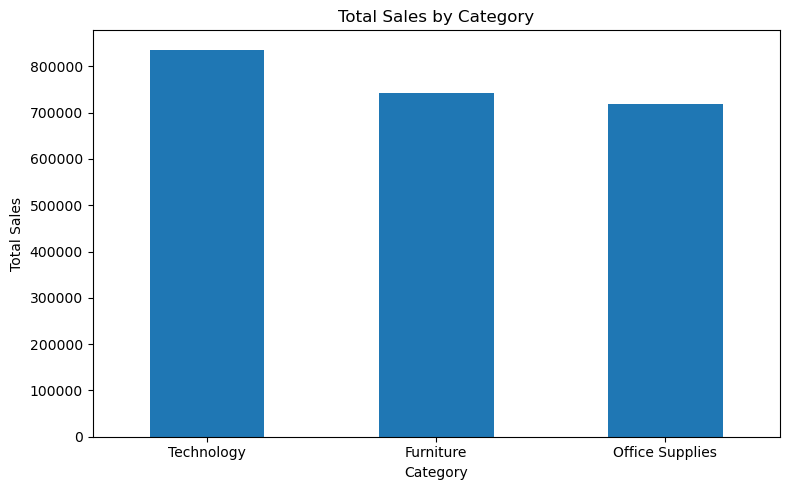

In [18]:
plt.figure(figsize=(8 ,5))
category_sales.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
print(category_profit)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18462.5924
Name: Profit, dtype: float64


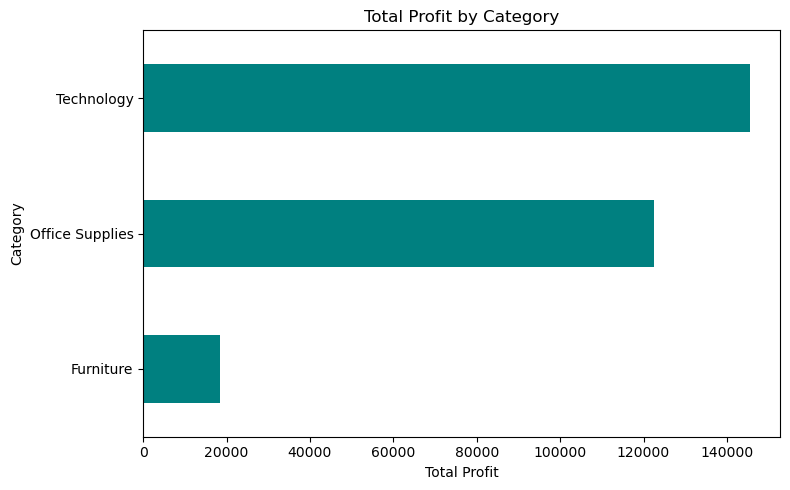

In [20]:
plt.figure(figsize=(8, 5))
category_profit.sort_values().plot(kind="barh", color="teal")
plt.title("Total Profit by Category")
plt.xlabel("Total Profit")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [21]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales.round(2))

Region
West       725457.82
East       678499.87
Central    501239.89
South      391716.98
Name: Sales, dtype: float64


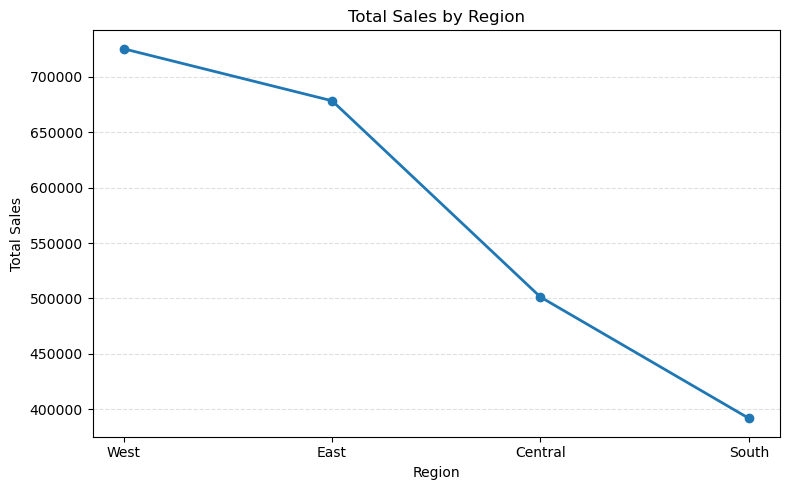

In [22]:
plt.figure(figsize=(8, 5))
plt.plot( region_sales.index,region_sales.values,
    marker="o", linewidth=2)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [23]:
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
print(segment_sales.round(2))

Segment
Consumer       1161401.34
Corporate       706141.44
Home Office     429371.78
Name: Sales, dtype: float64


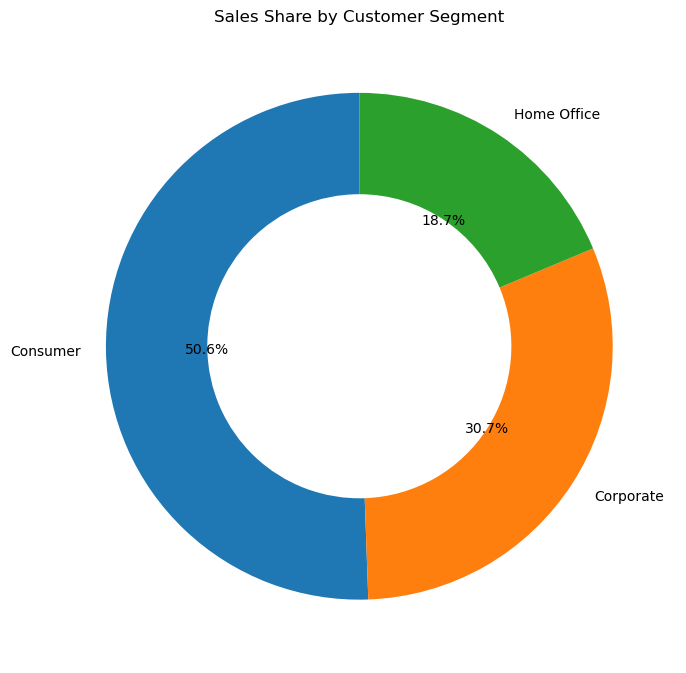

In [46]:
plt.figure(figsize=(7, 7))
plt.pie(segment_sales,labels=segment_sales.index,
    autopct="%1.1f%%",startangle=90,wedgeprops={"width": 0.4})
plt.title("Sales Share by Customer Segment")
plt.tight_layout()
plt.show()

In [25]:
df["Month"] = df["Order Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Sales"].sum()
print(monthly_sales.head(12).round(2))

Month
2014-01    14236.90
2014-02     4519.89
2014-03    55691.01
2014-04    28013.97
2014-05    23648.29
2014-06    34595.13
2014-07    33946.39
2014-08    27909.47
2014-09    81777.35
2014-10    31453.39
2014-11    78628.72
2014-12    69545.62
Freq: M, Name: Sales, dtype: float64


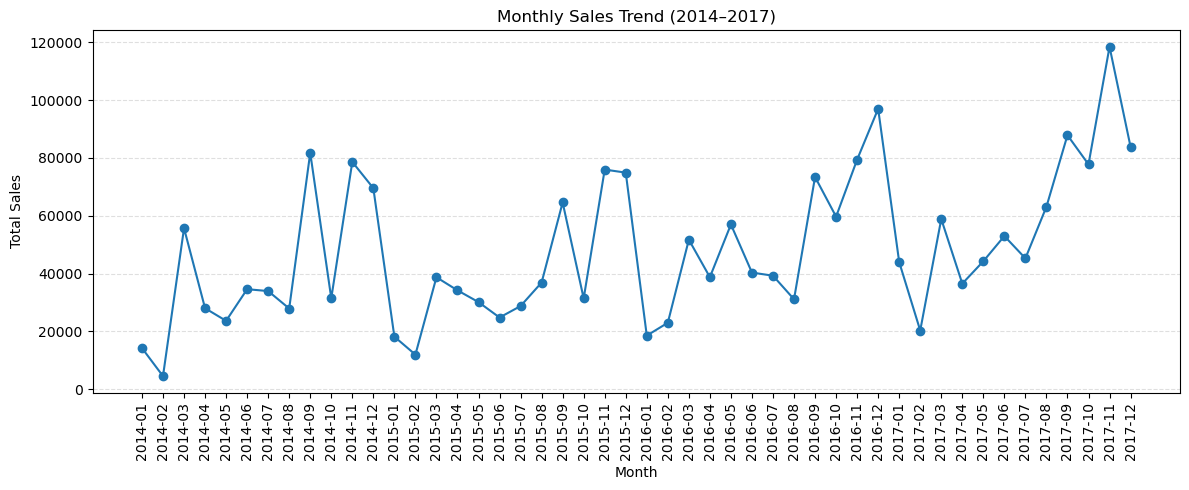

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str),monthly_sales.values,
    marker="o",linewidth=1.5)
plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [27]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
print(region_profit.round(2))

Region
West       108418.45
East        91534.84
South       46748.69
Central     39706.36
Name: Profit, dtype: float64


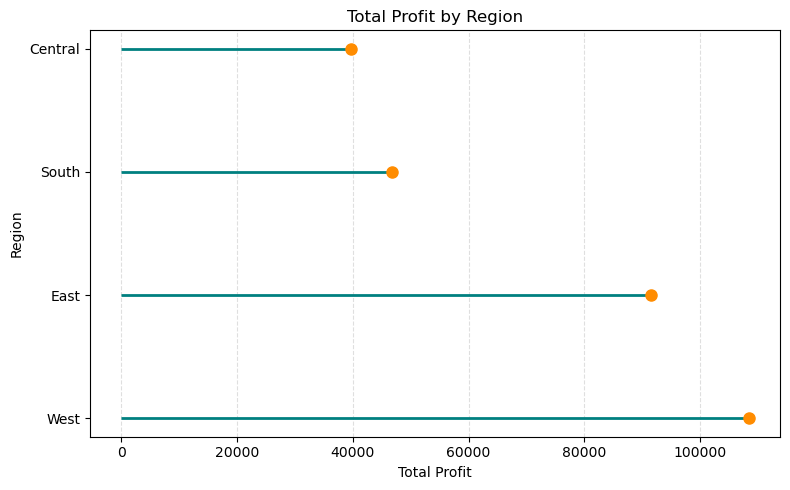

In [28]:
plt.figure(figsize=(8, 5))
plt.hlines(y=region_profit.index,xmin=0,
    xmax=region_profit.values,color="teal",linewidth=2)
plt.plot(region_profit.values,region_profit.index,
    "o",color="darkorange",markersize=8)
plt.title("Total Profit by Region")
plt.xlabel("Total Profit")
plt.ylabel("Region")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [29]:
subcategory_sales = (df.groupby("Sub-Category")["Sales"]
    .sum().sort_values(ascending=False))
print(subcategory_sales.round(2))

Sub-Category
Phones         330007.05
Chairs         328167.73
Storage        223843.61
Tables         206965.53
Binders        203412.73
Machines       189238.63
Accessories    167380.32
Copiers        149528.03
Bookcases      114880.00
Appliances     107532.16
Furnishings     91700.24
Paper           78479.21
Supplies        46673.54
Art             27118.79
Envelopes       16476.40
Labels          12486.31
Fasteners        3024.28
Name: Sales, dtype: float64


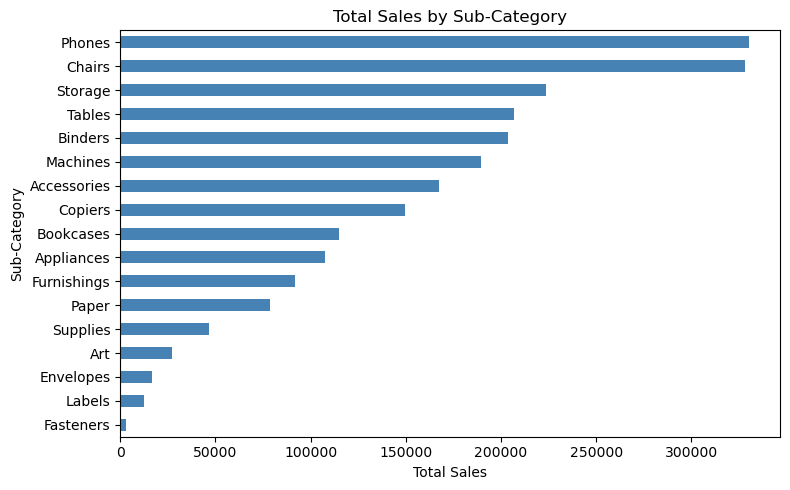

In [47]:
plt.figure(figsize=(8, 5))
subcategory_sales.sort_values().plot(kind="barh",color="steelblue")
plt.title("Total Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [31]:
subcategory_profit = (df.groupby("Sub-Category")["Profit"]
    .sum().sort_values(ascending=False))
print(subcategory_profit.round(2))

Sub-Category
Copiers        55617.82
Phones         44515.73
Accessories    41936.64
Paper          34053.57
Binders        30221.76
Chairs         26602.23
Storage        21278.83
Appliances     18138.01
Furnishings    13058.40
Envelopes       6964.18
Art             6527.79
Labels          5546.25
Machines        3384.76
Fasteners        949.52
Supplies       -1189.10
Bookcases      -3472.56
Tables        -17725.48
Name: Profit, dtype: float64


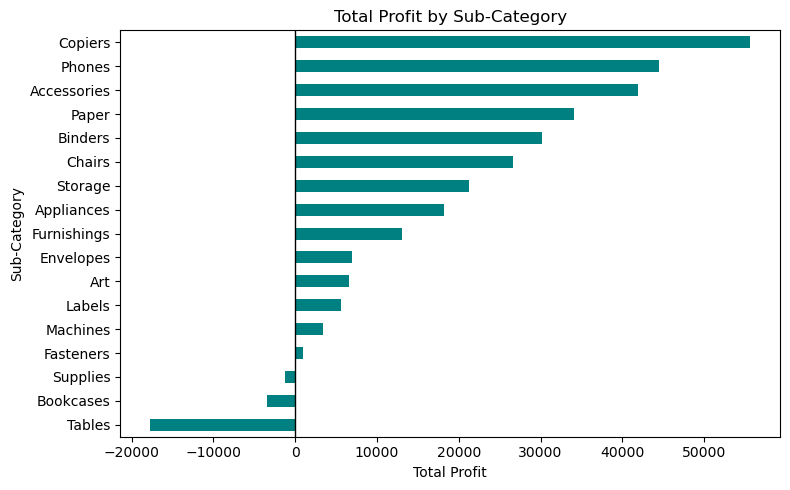

In [48]:
plt.figure(figsize=(8, 5))
subcategory_profit.sort_values().plot(kind="barh", color="teal")
plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.axvline(x=0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

In [33]:
subcategory_analysis = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
subcategory_analysis = subcategory_analysis.sort_values(by="Sales", ascending=False)
print(subcategory_analysis.round(2))

                  Sales    Profit
Sub-Category                     
Phones        330007.05  44515.73
Chairs        328167.73  26602.23
Storage       223843.61  21278.83
Tables        206965.53 -17725.48
Binders       203412.73  30221.76
Machines      189238.63   3384.76
Accessories   167380.32  41936.64
Copiers       149528.03  55617.82
Bookcases     114880.00  -3472.56
Appliances    107532.16  18138.01
Furnishings    91700.24  13058.40
Paper          78479.21  34053.57
Supplies       46673.54  -1189.10
Art            27118.79   6527.79
Envelopes      16476.40   6964.18
Labels         12486.31   5546.25
Fasteners       3024.28    949.52


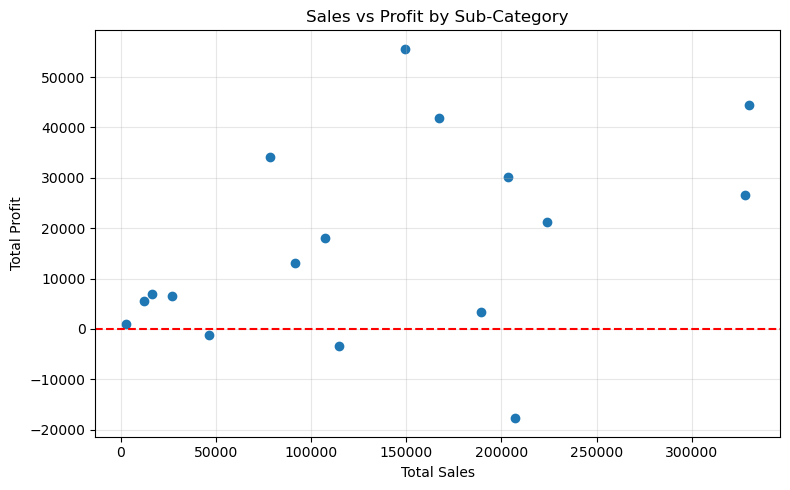

In [49]:
plt.figure(figsize=(8, 5))
plt.scatter(subcategory_analysis["Sales"],subcategory_analysis["Profit"])
plt.title("Sales vs Profit by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Total Profit")
plt.axhline(y=0, color="red", linestyle="--")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
print("Number of states:", df["State"].nunique())
print(sorted(df["State"].unique()))

Number of states: 49
['Alabama', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']


In [36]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [51]:
state_sales = df.groupby("State", as_index=False)["Sales"].sum()
state_sales["Sales"] = state_sales["Sales"].round(2)
print(state_sales.head())

        State      Sales
0     Alabama   19510.64
1     Arizona   35282.00
2    Arkansas   11678.13
3  California  457687.63
4    Colorado   32108.12


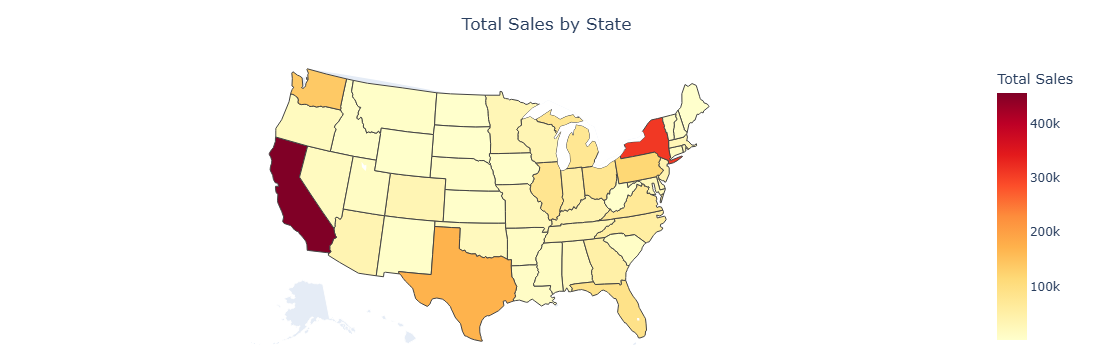

In [52]:
import plotly.express as px
state_codes = {
    "Alabama": "AL", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT",
    "Delaware": "DE", "District of Columbia": "DC",
    "Florida": "FL", "Georgia": "GA", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA",
    "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE",
    "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND",
    "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI",
    "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY"
}
state_sales = df.groupby("State", as_index=False)["Sales"].sum()
state_sales["State_Code"] = state_sales["State"].map(state_codes)
fig = px.choropleth(
    state_sales,
    locations="State_Code",
    locationmode="USA-states",
    color="Sales",
    scope="usa",
    color_continuous_scale="YlOrRd",
    hover_name="State",
    hover_data={"Sales": ":,.2f", "State_Code": False},
    title="Total Sales by State"
)
fig.update_layout(
    title_x=0.5,
    geo=dict(scope="usa", showlakes=True, lakecolor="white"),
    coloraxis_colorbar=dict(title="Total Sales"),
    margin=dict(l=10, r=10, t=60, b=10)
)
fig.show()

In [53]:
top_10_states = state_sales.sort_values(by="Sales", ascending=False).head(10)
print(top_10_states[["State", "Sales"]].round(2))

           State      Sales
3     California  457687.63
30      New York  310876.27
41         Texas  170188.05
45    Washington  138641.27
36  Pennsylvania  116511.91
8        Florida   89473.71
11      Illinois   80166.10
33          Ohio   77976.76
20      Michigan   76269.61
44      Virginia   70636.72


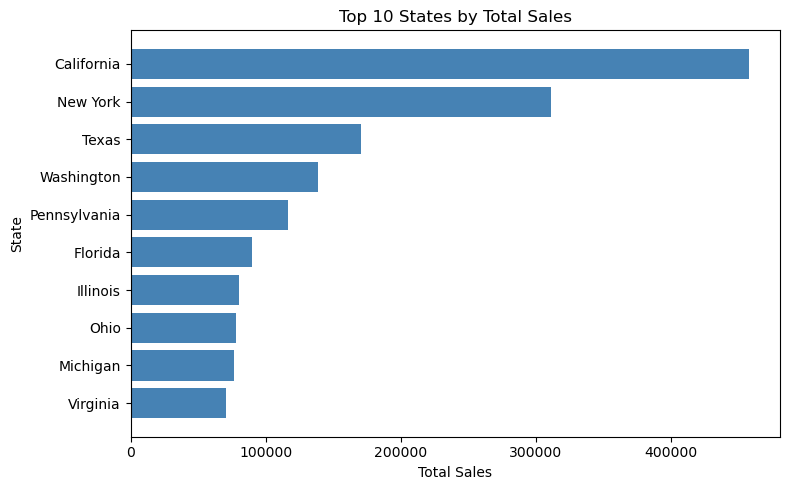

In [55]:
plt.figure(figsize=(8, 5))
top_10_states_sorted = top_10_states.sort_values("Sales")
plt.barh(top_10_states_sorted["State"],top_10_states_sorted["Sales"],color="steelblue")
plt.title("Top 10 States by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [56]:
state_profit = (df.groupby("State", as_index=False)["Profit"].sum()
    .sort_values(by="Profit", ascending=False))
print(state_profit.head(10).round(2))

         State    Profit
3   California  76381.39
30    New York  74038.55
45  Washington  33402.65
20    Michigan  24463.19
44    Virginia  18597.95
12     Indiana  18382.94
9      Georgia  16250.04
15    Kentucky  11199.70
21   Minnesota  10823.19
6     Delaware   9977.37


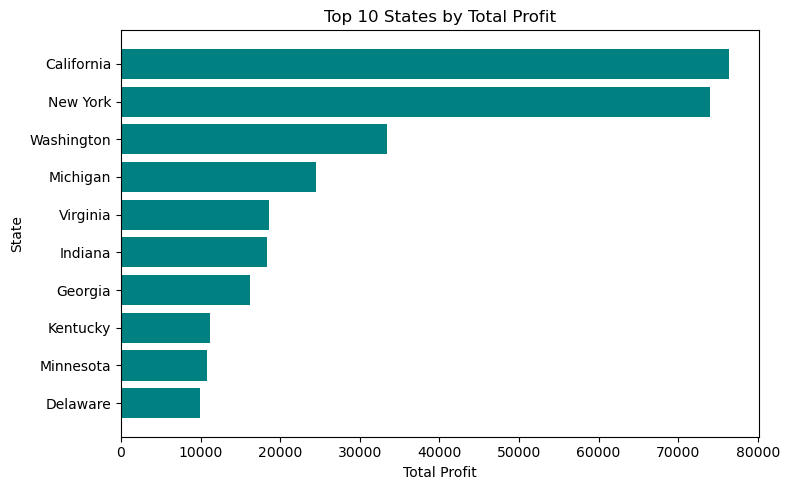

In [58]:
top_10_profit = state_profit.head(10).sort_values("Profit")
plt.figure(figsize=(8, 5))
plt.barh(top_10_profit["State"],top_10_profit["Profit"],color="teal")
plt.title("Top 10 States by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [59]:
bottom_5_states = state_profit.sort_values(by="Profit", ascending=True).head(5)
print(bottom_5_states.round(2))

             State    Profit
41           Texas -25729.36
33            Ohio -16959.32
36    Pennsylvania -15559.96
11        Illinois -12607.89
31  North Carolina  -7491.65


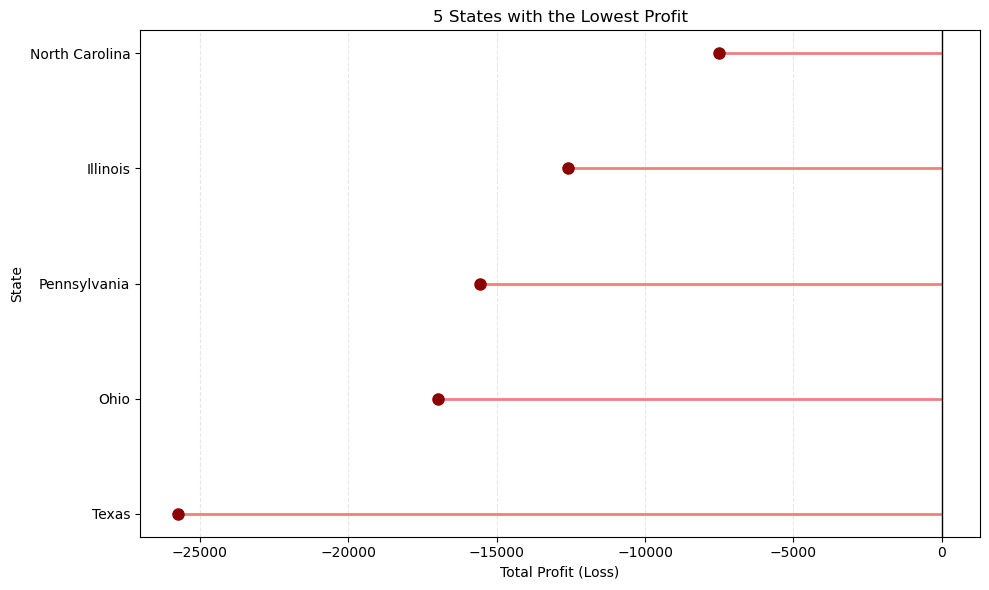

In [60]:
plt.figure(figsize=(10, 6))
bottom_5_sorted = bottom_5_states.sort_values("Profit")
plt.hlines(y=bottom_5_sorted["State"],xmin=bottom_5_sorted["Profit"],
    xmax=0,color="lightcoral",linewidth=2)
plt.plot(bottom_5_sorted["Profit"],bottom_5_sorted["State"],
    "o",color="darkred",markersize=8)
plt.title("5 States with the Lowest Profit")
plt.xlabel("Total Profit (Loss)")
plt.ylabel("State")
plt.axvline(x=0, color="black", linewidth=1)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Final Business Insights and Recommendations

### Key Findings

1. **Overall performance:** The dataset contains 9,992 records after duplicate removal, with total sales of 2,296,914.56 and total profit of 286,408.34.

2. **Category performance:** Technology generated the highest sales and profit among the three categories. Furniture generated substantial sales but comparatively low profit.

3. **Regional performance:** The West region recorded the highest sales and profit. The Central region generated more sales than the South but lower total profit.

4. **Customer segments:** The Consumer segment contributed the largest share of sales, followed by Corporate and Home Office.

5. **Monthly sales trends:** Sales varied across months during 2014–2017, showing the importance of monitoring monthly performance and seasonal patterns.

6. **Sub-category performance:** Copiers generated the highest profit, while Tables recorded the largest loss. Machines also generated relatively low profit compared with their sales.

7. **State performance:** California recorded the highest sales and profit among the states. Texas recorded the largest loss, followed by Ohio and Pennsylvania.

### Recommendations

- Investigate discounting, pricing, and costs associated with loss-making Furniture products, especially Tables.
- Review the performance of loss-making states, particularly Texas, Ohio, and Pennsylvania.
- Study the strategies behind the strong profit performance of Copiers and Accessories.
- Monitor monthly sales trends to support inventory and sales planning.
- Track both sales and profit when evaluating business performance instead of relying on sales alone.

### Conclusion

This project demonstrates how Python, pandas, Matplotlib, Seaborn, and Plotly can be used to clean data, calculate business metrics, explore sales and profitability, and communicate findings through charts and an interactive map.